In [4]:
## load data
import pandas as pd

df = pd.read_csv('daily.csv')
df

,date,username,followers,name,category,country,type,rank,also_in,countries
0,2026-09-25,433,79654283,433,Media,NL,org,56,NaN,NL
1,2026-09-25,9gag,51955772,9GAG: Go Fun The World,Media,HK,org,133,NaN,HK
2,2026-09-25,adele,55957481,Adele,Music,GB,person,118,NaN,GB
3,2026-09-25,agustd,55091406,SUGA of BTS 민윤기,Music,KR,person,121,NaN,KR
4,2026-09-25,akshaykumar,64955179,Akshay Kumar,Film & TV,IN,person,88,NaN,IN
...,...,...,...,...,...,...,...,...,...,...
38066,2026-10-31,zielu_94,1040223,Piotr Zielinski,Sports,PL,person,4726,NaN,PL
38067,2026-10-31,zlatan,65199951,Zlatan Ibrahimović,Sports,SE,person,87,NaN,SE
38068,2026-10-31,zoesaldana,11529571,Zoe Saldaña,Film & TV,US,person,973,NaN,US
38069,2026-10-31,zooeydeschanel,8081610,Zooey Deschanel,Music,US,person,1399,NaN,US


In [7]:
## EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()} \n')

print(f'Cek data duplicated \n {df.duplicated().sum()}')

Cek 5 data teratas 
           date        username  followers             name          category  \
9   2026-09-25    arianagrande  362665878    Ariana Grande             Music   
11  2026-09-25      badgalriri  145747032       badgalriri             Music   
20  2026-09-25  caradelevingne   38140255  Cara Delevingne  Fashion & beauty   
30  2026-09-25        ddlovato  147619850      Demi Lovato             Music   
55  2026-09-25             jlo  240059712   Jennifer Lopez             Music   

   country    type  rank           also_in countries  
9       US  person     7         Film & TV        US  
11      BB  person    29  Fashion & beauty        BB  
20      GB  person   217         Film & TV        GB  
30      US  person    28         Film & TV        US  
55      US  person    18         Film & TV        US   

Cek tipe data 
 date           str
username       str
followers    int64
name           str
category       str
country        str
type           str
rank         int6

In [6]:
## handle missing values
df.dropna(inplace=True)

C:\Users\mozar\AppData\Local\Temp\ipykernel_22776\4100555634.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [8]:
## outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,followers,26749481.5,147601804.5,120852323.0,-154529003.0,328880289.0,185,17.67
1,rank,28.0,335.0,307.0,-432.5,795.5,58,5.54


In [9]:
## handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
followers,185,17.669532
rank,58,5.539637


In [22]:
## split data
drop_cols = ['username', 'name', 'date', 'countries']
X = df.drop(columns=['followers', 'rank'] + drop_cols)
y = df['followers']

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
## training model
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# pipeline + training
lin_reg = make_pipeline(prep, LinearRegression())
lin_reg.fit(X_train, y_train)

# evaluasi
pred = lin_reg.predict(X_test)
print(f"R2   : {r2_score(y_test, pred):.4f}")
print(f"MAE  : {mean_absolute_error(y_test, pred):,.0f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

R2   : 0.5153
MAE  : 64,216,115
RMSE : 93,136,520


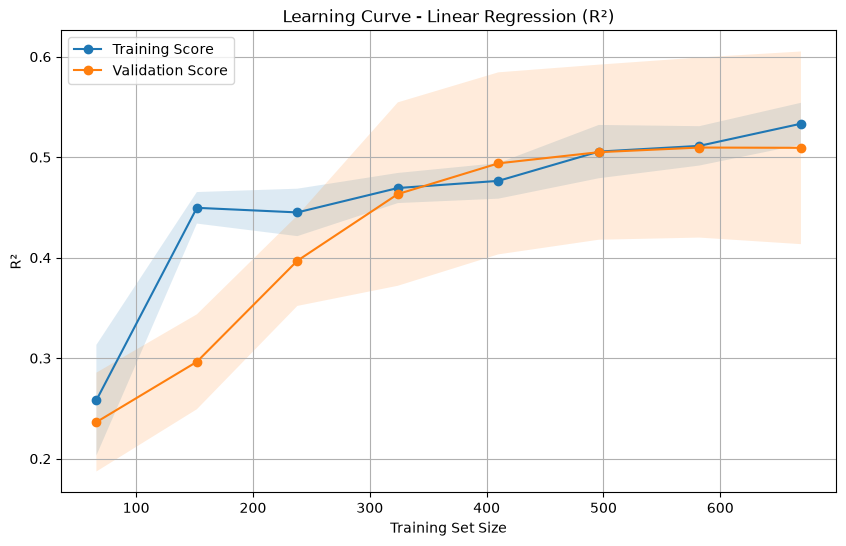

In [26]:
## learning curve
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    lin_reg, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=5,
    scoring='r2',
    n_jobs=-1
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.title('Learning Curve - Linear Regression (R²)')
plt.xlabel('Training Set Size')
plt.ylabel('R²')
plt.grid(True)
plt.legend()
plt.show()